# Анализ горизонтального смещения генетической модели SSH brute-force

**Цель:** отобразить фактический ряд 1–101 и результаты ГА-модели со сдвигом и без сдвига; рассчитать ошибки и локальную дисперсию ошибок в каждой точке.

- Обучение основной модели — наблюдения **1–60**; прогноз с обновлением по поступающим фактам — **61–101**.
- Для подбора горизонтального смещения используются **только обучающие точки 4–59**, в интервале от 0 до 1 шага влево.
- Горизонтально сдвинутая кривая — **ретроспективное сопоставление**, а не независимый прогноз: значение кривой правее целевой точки может зависеть от факта, полученного позже.
- **Дисперсия одного наблюдения не определена:** для каждой точки приводится квадрат ошибки и локальная выборочная дисперсия ошибок по последним пяти точкам. Дисперсия ошибок на всём участке рассчитывается отдельно.

Используются коэффициенты уже обученного ГА из предыдущей работы; повторно по контрольным 61–101 они не подгоняются.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.alpha': .25})
# Каждый элемент — количество SSH-инцидентов за 30 секунд.
y = np.array([21, 18, 21, 18, 18, 22, 16, 27, 26, 22, 19, 20, 24, 24, 25, 27, 24, 24, 20, 18, 17, 18, 23, 24, 19, 23, 26, 21, 24, 22, 23, 22, 19, 24, 22, 23, 20, 23, 20, 26, 22, 20, 25, 20, 21, 24, 21, 25, 27, 21, 16, 22, 21, 20, 22, 18, 19, 26, 22, 25, 21, 23, 29, 24, 24, 23, 24, 26, 23, 25, 17, 23, 16, 23, 25, 17, 22, 18, 26, 22, 24, 22, 18, 20, 23, 23, 21, 17, 22, 24, 21, 23, 19, 24, 18, 23, 20, 20, 23, 24, 22], dtype=float)
assert len(y) == 101
x = np.arange(1, 102)
train = y[:60]
mu = np.mean(train)
print('Число наблюдений:', len(y), 'Среднее на обучении:', round(mu, 4))

Число наблюдений: 101 Среднее на обучении: 21.8333


## 1. Восстановление исходной функции, выбранной генетическим алгоритмом

Для выбранной ГА-функции использована **обратная зависимость третьей степени** и три лаговых поправки:

\[\hat y_t=a+\frac{b}{(1+t/15)^3}+\beta_0+\gamma_1(y_{t-1}-\mu)+\gamma_2(y_{t-2}-\mu)+\gamma_3(y_{t-3}-\mu).\]

Коэффициенты \(a,b\) определяются методом МНК по 1–60; \(\beta_0,\gamma_1,\gamma_2,\gamma_3\) — результаты предыдущей ГА-оптимизации и здесь не меняются.

In [2]:
# Коэффициенты предыдущего генетического алгоритма
GA_BIAS = -0.6037238731061447
GA_GAMMAS = np.array([-0.1294236048362728, -0.10230646344638802, 0.45], dtype=float)

feature = (1 + np.arange(1, 61) / 15.0) ** (-3)
a, b = np.linalg.lstsq(
    np.column_stack([np.ones(60), feature]), train, rcond=None
)[0]
CAP = max(35.0, float(train.max() + 4 * np.std(train)))

def predict_ga(t, history):
    """Один шаг модели в точке t: history содержит только значения ДО t."""
    prev = np.asarray(history[-3:], float)
    if len(prev) < 3:
        prev = np.r_[np.full(3-len(prev), mu), prev]
    inverse = a + b/(1 + t/15.0)**3
    dynamic = np.dot(GA_GAMMAS, prev[::-1] - mu)
    return float(np.clip(inverse + GA_BIAS + dynamic, 0, CAP))

# 1..60: fitted values on training points with true past history.
# 61..101: rolling one-step forecast, at each t only facts 1..t-1 known.
# 102..104: recursive extension for the right edge of shifted display.
forecast_full = []
history = []
for t in range(1, 105):
    estimate = predict_ga(t, history)
    forecast_full.append(estimate)
    if t <= 101:
        history.append(float(y[t-1]))
    else:
        history.append(estimate)
forecast_full = np.array(forecast_full)
forecast = forecast_full[:101]
print(f'Обратная часть: {a:.6f} {b:+.6f}/(1+t/15)^3')
print('Смещение ГА:', GA_BIAS, 'коэффициенты лагов:', GA_GAMMAS)
print('Прогноз 61-го наблюдения:', round(forecast[60], 4))

Обратная часть: 22.213992 -3.398425/(1+t/15)^3
Смещение ГА: -0.6037238731061447 коэффициенты лагов: [-0.1294236  -0.10230646  0.45      ]
Прогноз 61-го наблюдения: 23.0322


## 2. Подбор небольшого горизонтального смещения

Для сдвига влево на \(\delta\) шага строится **та же кривая**, но в точке \(t\) считывается её значение в \(t+\delta\):

\[\hat y^{\mathrm{сдв}}(t)=\hat y(t+\delta).\]

Непрерывное значение между 30-секундными точками рассчитывается линейной интерполяцией. Сдвиг выбирается только по 4–59, не по 61–101. Интервал поиска: от 0 до 1 шага с шагом 0,05.

Сдвиг влево = 0.25 наблюдения = 7.5 секунды
MAE на обучающих точках 4–59:
  Без сдвига: 2.5901
  Со сдвигом: 2.5711


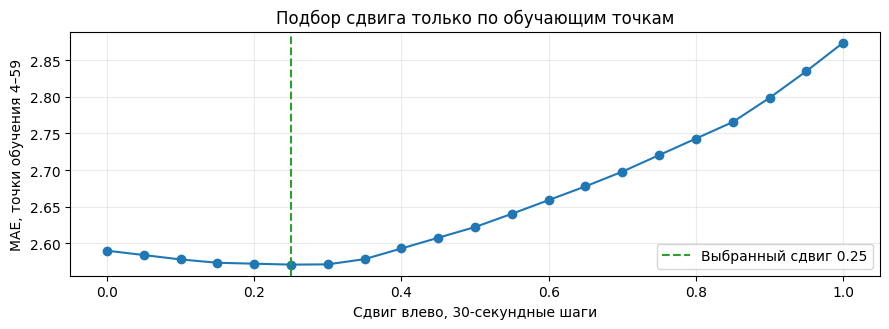

In [3]:
lookups = np.arange(1, 105, dtype=float)
training_eval = np.arange(3, 59)  # 0-based индексы: точки 4..59
candidate_shifts = np.round(np.arange(0, 1.001, .05), 8)

# delta >0 — перенос кривой влево, но этот способ ретроспективен
train_scores = []
for delta in candidate_shifts:
    shifted_check = np.interp(x[training_eval] + delta, lookups, forecast_full)
    train_scores.append(np.mean(np.abs(y[training_eval]-shifted_check)))

shift = float(candidate_shifts[np.argmin(train_scores)])
shifted = np.interp(x + shift, lookups, forecast_full)
print(f'Сдвиг влево = {shift:.2f} наблюдения = {30*shift:.1f} секунды')
print('MAE на обучающих точках 4–59:')
print(f'  Без сдвига: {train_scores[0]:.4f}')
print(f'  Со сдвигом: {min(train_scores):.4f}')

plt.figure(figsize=(9, 3.4))
plt.plot(candidate_shifts, train_scores, 'o-')
plt.axvline(shift, color='tab:green', linestyle='--', label=f'Выбранный сдвиг {shift:.2f}')
plt.xlabel('Сдвиг влево, 30-секундные шаги')
plt.ylabel('MAE, точки обучения 4–59')
plt.title('Подбор сдвига только по обучающим точкам')
plt.legend(); plt.tight_layout(); plt.show()

## 3. Ошибка, квадрат ошибки и локальная дисперсия для каждой точки

Для каждого наблюдения \(t\):

\[e_t=y_t-\hat y_t,\qquad e_t^2=(y_t-\hat y_t)^2.\]

Вместо невозможной «дисперсии одной точки» рассчитывается **локальная выборочная дисперсия ошибок пяти последних наблюдений**: \(s_t^2=\mathrm{Var}(e_{t-4},\ldots,e_t)\), если доступно хотя бы два значения. Для первой точки она не определена и остаётся пустой.

In [4]:
err0 = y - forecast
err1 = y - shifted
var0 = pd.Series(err0).rolling(5, min_periods=2).var(ddof=1)
var1 = pd.Series(err1).rolling(5, min_periods=2).var(ddof=1)

details = pd.DataFrame({
    'Точка': x,
    'Участок': np.where(x <= 60, 'Обучение', 'Контроль'),
    'Факт': y,
    'ГА без сдвига': forecast,
    'ГА со сдвигом': shifted,
    'Ошибка без сдвига': err0,
    'Ошибка со сдвигом': err1,
    '|Ошибка| без сдвига': np.abs(err0),
    '|Ошибка| со сдвигом': np.abs(err1),
    'Квадрат ошибки без сдвига': err0**2,
    'Квадрат ошибки со сдвигом': err1**2,
    'Локальная дисперсия, без сдвига (окно 5)': var0,
    'Локальная дисперсия, со сдвигом (окно 5)': var1,
})

def evaluate(truth, pred):
    error = truth - pred
    return {'MAE': np.mean(np.abs(error)),
            'MSE': np.mean(error**2),
            'RMSE': np.sqrt(np.mean(error**2)),
            'MAPE, %': 100*np.mean(np.abs(error/truth)),
            'Выборочная дисперсия ошибок': np.var(error, ddof=1)}

rows=[]
for region, index in [('Обучение 4–59', training_eval),
                      ('Контроль 61–101', np.arange(60,101)),
                      ('Весь ряд 1–101', np.arange(101))]:
    for name, pred in [('Без сдвига', forecast), ('Со сдвигом (ретроспективно)', shifted)]:
        rows.append({'Участок': region, 'Вариант': name, **evaluate(y[index],pred[index])})
summary = pd.DataFrame(rows)
print('Сводные ошибки и выборочная дисперсия:')
display(summary.round(4))
print('Поточечные расчёты:')
display(details.round(4))

Сводные ошибки и выборочная дисперсия:


,Участок,Вариант,MAE,MSE,RMSE,"MAPE, %",Выборочная дисперсия ошибок
0,Обучение 4–59,Без сдвига,2.5901,9.8843,3.1439,11.9552,9.7289
1,Обучение 4–59,Со сдвигом (ретроспективно),2.5711,9.8795,3.1432,11.8520,9.7229
2,Контроль 61–101,Без сдвига,2.6806,10.3886,3.2231,12.6929,10.5329
3,Контроль 61–101,Со сдвигом (ретроспективно),2.5630,9.5303,3.0871,12.1175,9.6482
4,Весь ряд 1–101,Без сдвига,2.6182,10.0315,3.1673,12.2006,9.8578
5,Весь ряд 1–101,Со сдвигом (ретроспективно),2.5531,9.6067,3.0995,11.8852,9.4367


Поточечные расчёты:


,Точка,Участок,Факт,ГА без сдвига,ГА со сдвигом,Ошибка без сдвига,Ошибка со сдвигом,|Ошибка| без сдвига,|Ошибка| со сдвигом,Квадрат ошибки без сдвига,Квадрат ошибки со сдвигом,"Локальная дисперсия, без сдвига (окно 5)","Локальная дисперсия, со сдвигом (окно 5)"
0,1,Обучение,21.0,18.8101,18.9534,2.1899,2.0466,2.1899,2.0466,4.7959,4.1885,NaN,NaN
1,2,Обучение,18.0,19.3836,19.5939,-1.3836,-1.5939,1.3836,1.5939,1.9142,2.5406,6.3850,6.6266
2,3,Обучение,21.0,20.2250,20.1845,0.7750,0.8155,0.7750,0.8155,0.6007,0.6650,3.2386,3.4290
3,4,Обучение,18.0,20.0631,19.8055,-2.0631,-1.8055,2.0631,1.8055,4.2563,3.2600,3.8364,3.5273
4,5,Обучение,18.0,19.0329,19.4960,-1.0329,-1.4960,1.0329,1.4960,1.0670,2.2379,3.0438,3.0163
...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,97,Контроль,20.0,22.8183,22.1125,-2.8183,-2.1125,2.8183,2.1125,7.9427,4.4628,10.8426,8.3162
97,98,Контроль,20.0,19.9952,20.6345,0.0048,-0.6345,0.0048,0.6345,0.0000,0.4026,9.0914,6.7169
98,99,Контроль,23.0,22.5524,22.1178,0.4476,0.8822,0.4476,0.8822,0.2004,0.7782,6.9091,5.0698
99,100,Контроль,24.0,20.8143,20.7053,3.1857,3.2947,3.1857,3.2947,10.1487,10.8553,5.4934,4.4392


## 4. Графики

Зелёная кривая сдвинута влево относительно оранжевой; фактические данные не перемещаются. На контроле 61–101 сдвиг показан **только для последующего графического сопоставления**, а не как новый строгий прогноз.

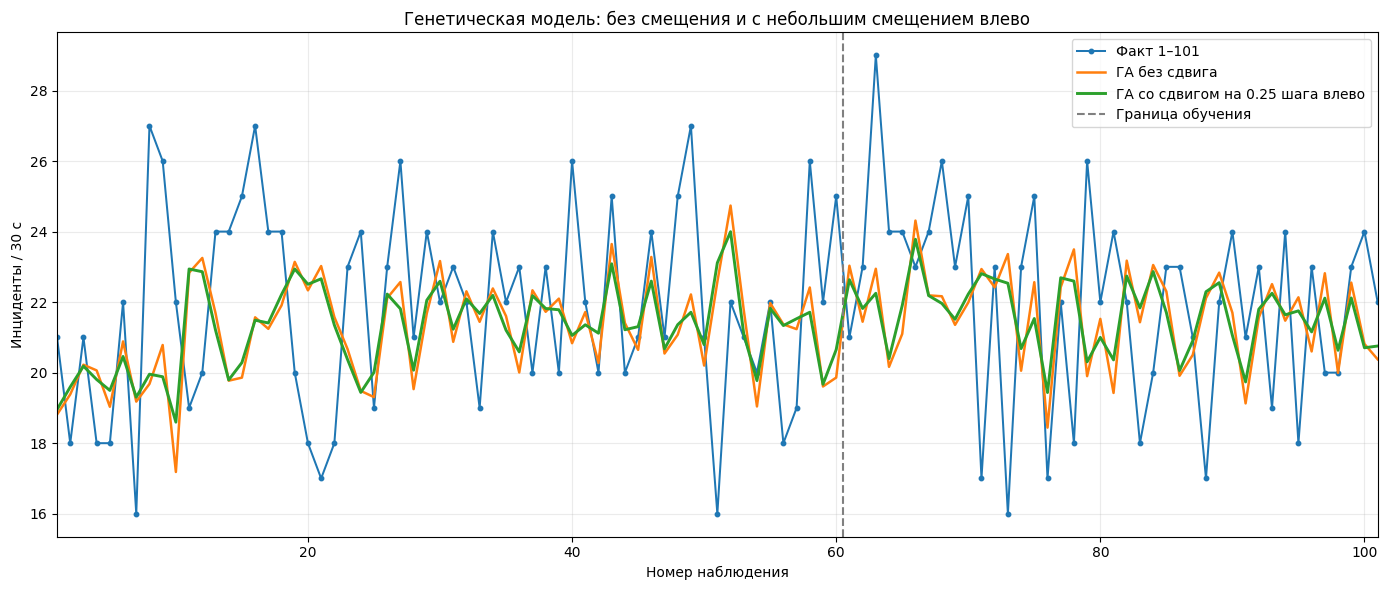

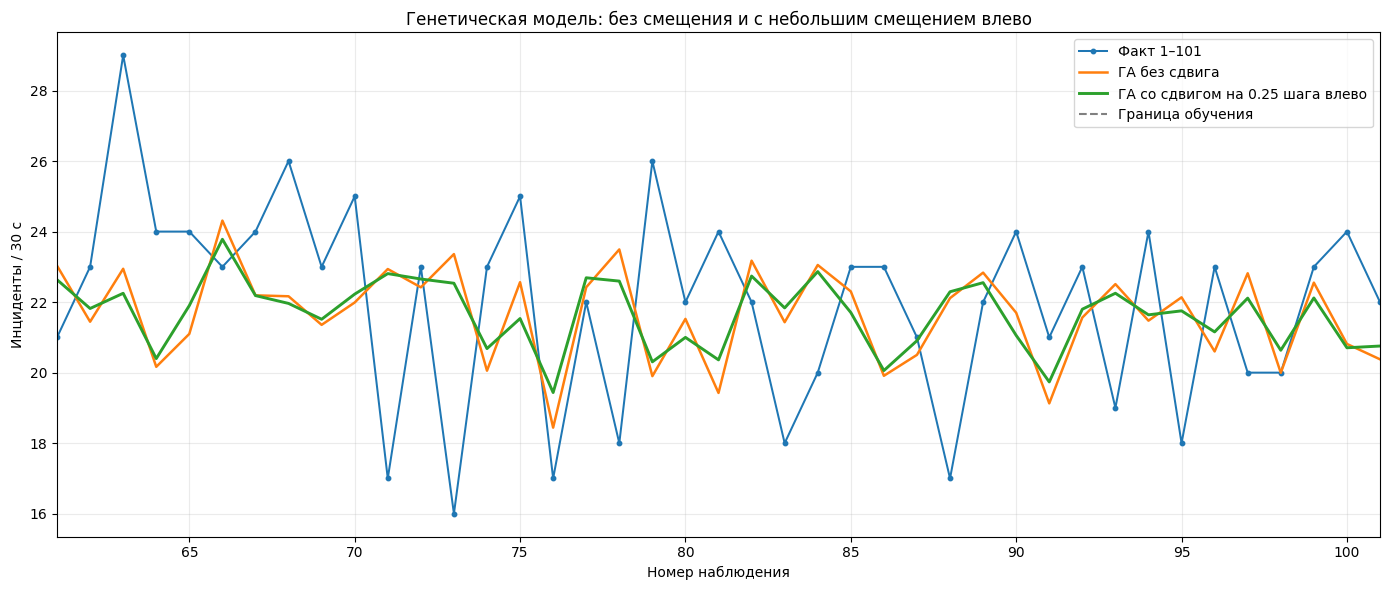

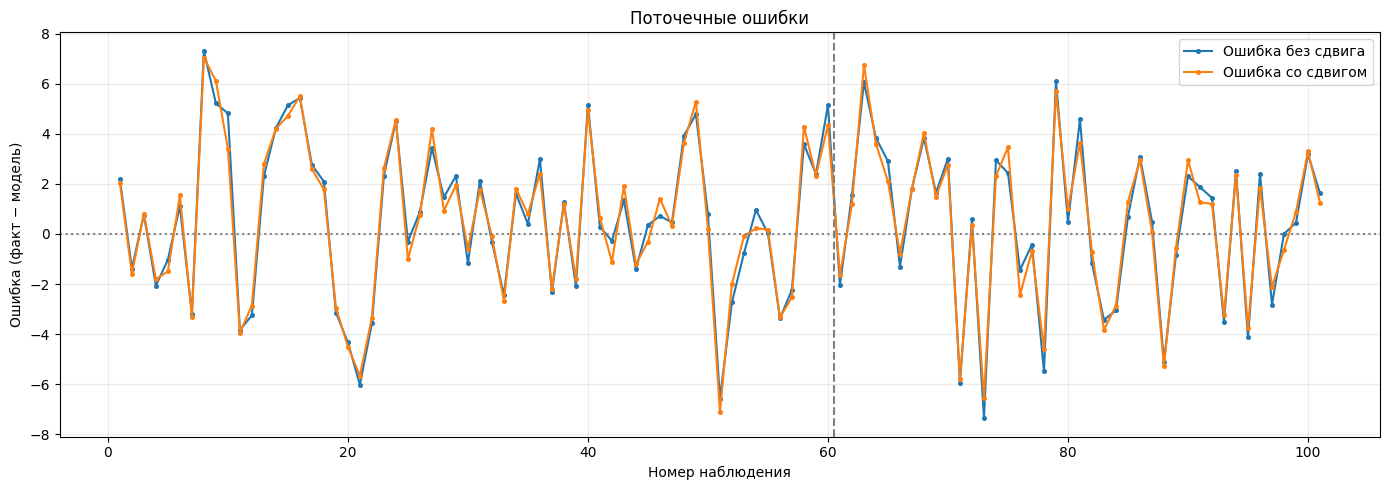

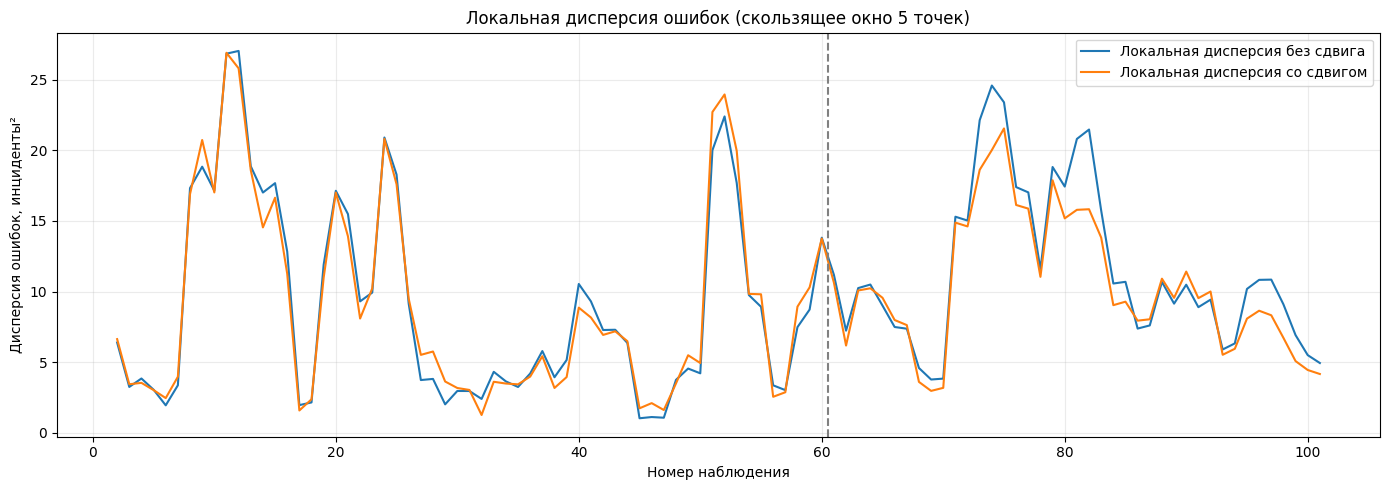

In [5]:
def plot_compare(xmin=1, xmax=101):
    plt.figure(figsize=(14,6))
    plt.plot(x, y, '-o', lw=1.45, ms=3.2, label='Факт 1–101')
    plt.plot(x, forecast, lw=1.8, label='ГА без сдвига')
    plt.plot(x, shifted, lw=2.1, label=f'ГА со сдвигом на {shift:.2f} шага влево')
    plt.axvline(60.5, color='gray', linestyle='--', label='Граница обучения')
    plt.xlabel('Номер наблюдения'); plt.ylabel('Инциденты / 30 с')
    plt.title('Генетическая модель: без смещения и с небольшим смещением влево')
    plt.xlim(xmin, xmax); plt.legend(); plt.tight_layout(); plt.show()

plot_compare(1,101)
plot_compare(61,101)

plt.figure(figsize=(14,5))
plt.plot(x, err0, '-o', ms=2.6, label='Ошибка без сдвига')
plt.plot(x, err1, '-o', ms=2.6, label='Ошибка со сдвигом')
plt.axhline(0, color='gray', linestyle=':')
plt.axvline(60.5, color='gray', linestyle='--')
plt.xlabel('Номер наблюдения');plt.ylabel('Ошибка (факт − модель)')
plt.title('Поточечные ошибки');plt.legend();plt.tight_layout();plt.show()

plt.figure(figsize=(14,5))
plt.plot(x, var0, label='Локальная дисперсия без сдвига')
plt.plot(x, var1, label='Локальная дисперсия со сдвигом')
plt.axvline(60.5, color='gray', linestyle='--')
plt.xlabel('Номер наблюдения'); plt.ylabel('Дисперсия ошибок, инциденты²')
plt.title('Локальная дисперсия ошибок (скользящее окно 5 точек)')
plt.legend();plt.tight_layout();plt.show()

## 5. Экспорт и интерпретация

При сдвиге \(\hat y(t+\delta)\) значение правее точки \(t\) может зависеть от факта \(y_t\), доступного только после окончания интервала. Поэтому улучшение ошибки со сдвигом **не доказывает** повышение качества прогноза неизвестного будущего. Для честной оценки реального прогноза следует использовать колонку «ГА без сдвига» или заново обучить модель с временным сдвигом цели и строго причинными признаками.

In [6]:
details.to_csv('ГА_поточечные_ошибки_дисперсии_1_101.csv', index=False, encoding='utf-8-sig')
summary.to_csv('ГА_сравнение_метрик_сдвиг_без_сдвига.csv', index=False, encoding='utf-8-sig')
print('Экспортированы два CSV: поточечные расчёты и сводные метрики.')

Экспортированы два CSV: поточечные расчёты и сводные метрики.
